# 02 · Modelling

The models and numbers come from two scripts:

- `python -m src.models.train`: tunes each model family on 2010–2023 using yearly folds
  (train on every earlier year, validate on 2019, 2020, ... 2023).
- `python -m src.models.evaluate`: walk-forward evaluation (refit every quarter), the
  calibrated 80% range, and the final models for the app.

This notebook reads their outputs and explains them. **2024–2026 is never used to choose anything.**

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from src.config import PROCESSED_DIR
from src.models.dataset import TARGET, load_features
from src.models.train import MODELS_DIR
from src.viz import AQUA, BLUE, GAIN, LOSS, NEUTRAL, ORANGE, TEXT_SECONDARY, apply_style, save

apply_style()
pd.set_option("display.float_format", "{:.2f}".format)
NAMES = {"median": "Median of all past IPOs", "bucket_median": "Median of same subscription bucket",
         "ridge": "Ridge regression", "random_forest": "Random forest", "lightgbm": "LightGBM"}

D:\Ck\IMARTICUS\github\personal-projects\imarticus projects\ML\ipo-listing-predictor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Tuning (2019–2023 yearly folds)

In [2]:
cv = pd.read_csv(PROCESSED_DIR / "cv_results.csv")
best_cv = cv.sort_values("mae").groupby("model").head(1).set_index("model")[["mae", "median_ae", "spearman", "params", "data"]]
best_cv.rename(index=NAMES).sort_values("mae")

,mae,median_ae,spearman,params,data
model,,,,,
Random forest,16.03,9.59,0.76,"{""max_depth"": 8, ""min_samples_leaf"": 5}","{""features"": ""base"", ""half_life"": null}"
LightGBM,16.45,9.73,0.74,"{""n_estimators"": 200, ""num_leaves"": 15, ""min_c...","{""features"": ""base"", ""half_life"": null}"
Median of same subscription bucket,17.21,10.12,0.71,{},{}
Ridge regression,18.71,11.61,0.73,"{""alpha"": 30}","{""features"": ""base"", ""half_life"": null}"
Median of all past IPOs,26.74,13.10,-0.02,{},{}


Every ML model beats "predict the median" by a wide margin, and the forest and LightGBM beat the
subscription-bucket lookup. Relative-subscription features and recency weighting were options in the
search; neither won on these folds.

## 2. First test: a model frozen at the end of 2023

In [3]:
frozen = pd.read_csv(PROCESSED_DIR / "frozen_test_results.csv").set_index("model")
frozen.rename(index=NAMES)[["cv_mae", "mae", "median_ae", "spearman"]]

,cv_mae,mae,median_ae,spearman
model,,,,
Random forest,16.03,22.03,13.54,0.69
LightGBM,16.45,24.61,14.25,0.67
Median of same subscription bucket,17.21,17.94,12.51,0.69
Ridge regression,18.71,21.29,16.65,0.65
Median of all past IPOs,26.74,18.98,9.30,0.00


Trained once on 2010–2023 and left alone, every ML model did **worse** on 2024–2026 than the
simple bucket lookup. The cause is a shift in the market, not a bug:

In [4]:
f = load_features()
f["sub_bucket"] = pd.cut(f["sub_total"], [0, 3, 10, 30, 100, 1e5], labels=["<3x", "3–10x", "10–30x", "30–100x", "100x+"])
f["era"] = pd.cut(f["year"], [2009, 2019, 2023, 2026], labels=["2010–2019", "2020–2023", "2024–2026"])
drift = f.pivot_table(index="sub_bucket", columns="era", values=TARGET, aggfunc="median", observed=True)
drift.loc["Median subscription (x)"] = f.groupby("era", observed=True)["sub_total"].median()
drift

era,2010–2019,2020–2023,2024–2026
sub_bucket,,,
<3x,-0.12,0.14,-1.00
3–10x,4.23,3.79,0.00
10–30x,11.34,12.65,6.52
30–100x,25.08,36.88,14.12
100x+,59.19,75.00,36.52
Median subscription (x),4.85,22.57,28.02


**Subscription inflation.** The median IPO went from about 5x subscribed before 2020 to 28x after
2023, and the gain that came with a given level of demand roughly halved (100x+ issues: 75% median
gain in 2020–23, 36% in 2024–26). A model frozen in 2023 still believes in the 2021 frenzy.

## 3. Walk-forward: refit every quarter, as you would in real use

In [5]:
wf = pd.read_csv(PROCESSED_DIR / "wf_results.csv")
table = wf.pivot(index="model", columns="period", values=["mae", "median_ae", "spearman"])
table.rename(index=NAMES).sort_values(("mae", "2019-2023"))

mae           median_ae            \
period                             2019-2023 2024-2026 2019-2023 2024-2026   
model                                                                        
Random forest                          16.13     19.52      9.15     12.13   
LightGBM                               16.23     20.92      9.96     12.21   
Median of same subscription bucket     17.27     17.26     10.12     11.83   
Ridge regression                       18.69     20.08     12.01     15.84   
Median of all past IPOs                26.70     19.06     12.92      9.73   

                                    spearman            
period                             2019-2023 2024-2026  
model                                                   
Random forest                           0.76      0.71  
LightGBM                                0.75      0.68  
Median of same subscription bucket      0.70      0.67  
Ridge regression                        0.73      0.65  
Median of all past IPOs                 0.03     -0.17

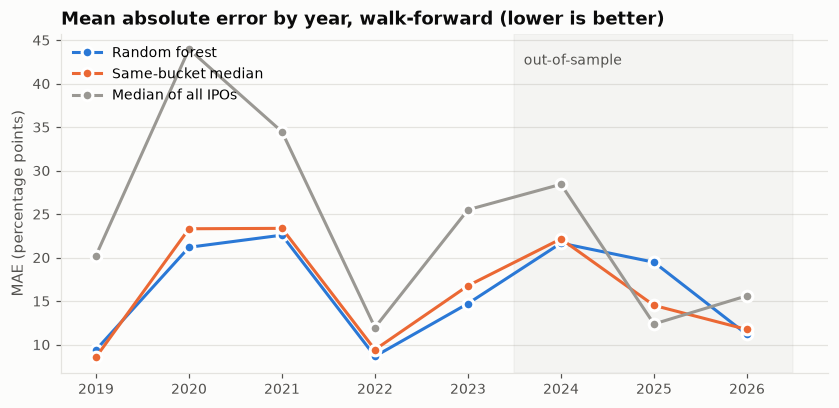

,median,bucket_median,random_forest
year,,,
2019,20.24,8.56,9.40
2020,43.97,23.32,21.19
2021,34.48,23.37,22.59
2022,11.97,9.42,8.66
2023,25.51,16.78,14.72
2024,28.43,22.16,21.67
2025,12.38,14.51,19.48
2026,15.61,11.74,11.17


In [6]:
pred = pd.read_csv(PROCESSED_DIR / "wf_predictions.csv", parse_dates=["listing_date"])
by_year = pred.groupby("year").apply(
    lambda g: pd.Series({m: (g[m] - g[TARGET]).abs().mean() for m in ["median", "bucket_median", "random_forest"]}),
    include_groups=False)

fig, ax = plt.subplots(figsize=(9, 4))
for column, color, label in [("random_forest", BLUE, "Random forest"),
                             ("bucket_median", ORANGE, "Same-bucket median"),
                             ("median", NEUTRAL, "Median of all IPOs")]:
    ax.plot(by_year.index, by_year[column], color=color, linewidth=2, marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=2, label=label)
ax.axvspan(2023.5, 2026.5, color=NEUTRAL, alpha=0.08)
ax.text(2023.6, ax.get_ylim()[1] * 0.95, "out-of-sample", color=TEXT_SECONDARY, fontsize=9, va="top")
ax.set_title("Mean absolute error by year, walk-forward (lower is better)")
ax.set_ylabel("MAE (percentage points)")
ax.set_xticks(by_year.index)
ax.legend(loc="upper left")
save(fig, "07_error_by_year")
plt.show()
by_year

Point model, picked on 2019–2023: **random forest** (lowest MAE, best rank correlation).

On 2024–2026 its rank correlation is the best of all models (0.71). Its absolute error, though, is
higher than the bucket lookup's, mostly from 2025, when every IPO listed lower than history
suggested. Predicting the exact gain in a shifting market is hard. **Ordering IPOs from best to
worst**, which is what an apply-or-skip decision needs, is where the model adds value. Phase 5
tests that directly.

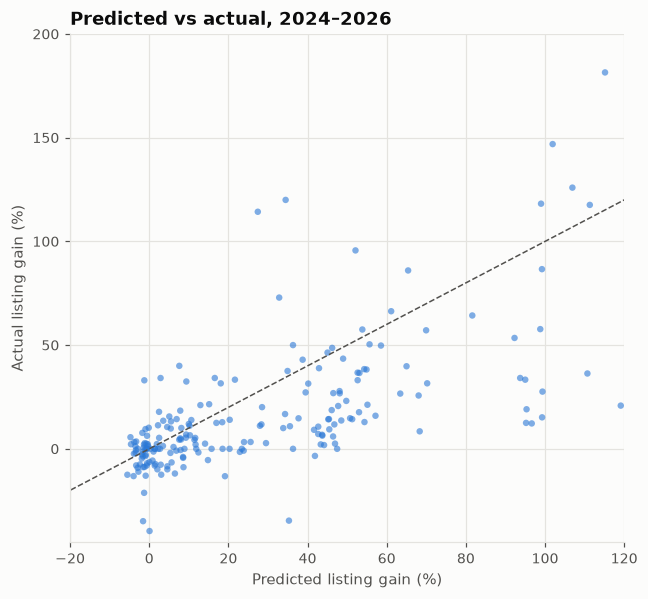

In [7]:
test = pred[pred["year"] >= 2024]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(test["random_forest"], test[TARGET], s=18, color=BLUE, alpha=0.6, edgecolor="none")
lims = [-45, 200]
ax.plot(lims, lims, color=TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.set_xlim(-20, 120); ax.set_ylim(*lims)
ax.set_title("Predicted vs actual, 2024–2026")
ax.set_xlabel("Predicted listing gain (%)")
ax.set_ylabel("Actual listing gain (%)")
ax.grid(axis="x", visible=True)
save(fig, "08_pred_vs_actual")
plt.show()

## 4. The 80% range

In [8]:
ranges = pd.read_csv(PROCESSED_DIR / "range_results.csv")
ranges

,period,raw_coverage,raw_width,coverage,width,pinball_p50
0,2019-2023,0.67,36.73,0.78,47.67,8.40
1,2024-2026,0.56,41.63,0.79,56.84,9.02


Plain quantile models were overconfident: the P10–P90 band caught only 56–67% of outcomes instead
of 80%. Rolling **conformal calibration** fixes this. It looks at how far recent actuals fell
outside their ranges and widens new ranges by that much. Set to 80% up front (no tuning), it delivered 78% on 2019–2023 and **79% on 2024–2026**.

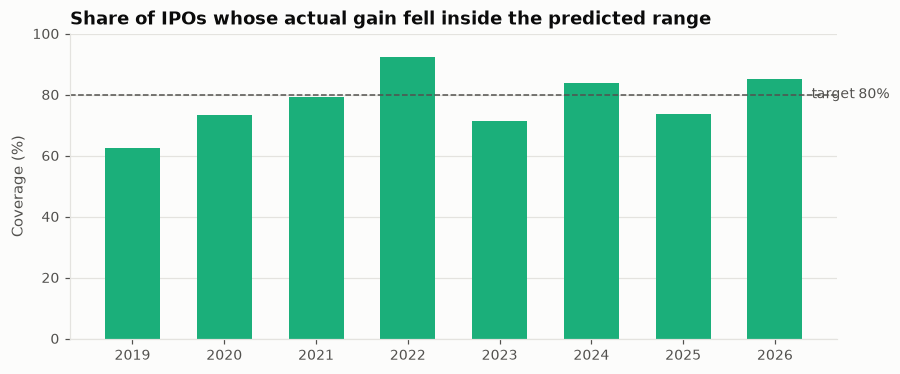

In [9]:
cover = pred.assign(inside=(pred[TARGET] >= pred["low"]) & (pred[TARGET] <= pred["high"]))
cover_year = cover.groupby("year")["inside"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(cover_year.index, cover_year.values, color=AQUA, width=0.6)
ax.axhline(80, color=TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.text(cover_year.index.max() + 0.4, 80, "target 80%", va="center", fontsize=9, color=TEXT_SECONDARY)
ax.set_ylim(0, 100)
ax.set_title("Share of IPOs whose actual gain fell inside the predicted range")
ax.set_ylabel("Coverage (%)")
ax.set_xticks(cover_year.index)
save(fig, "09_range_coverage")
plt.show()

## 5. What the model looks at (SHAP, final random forest)

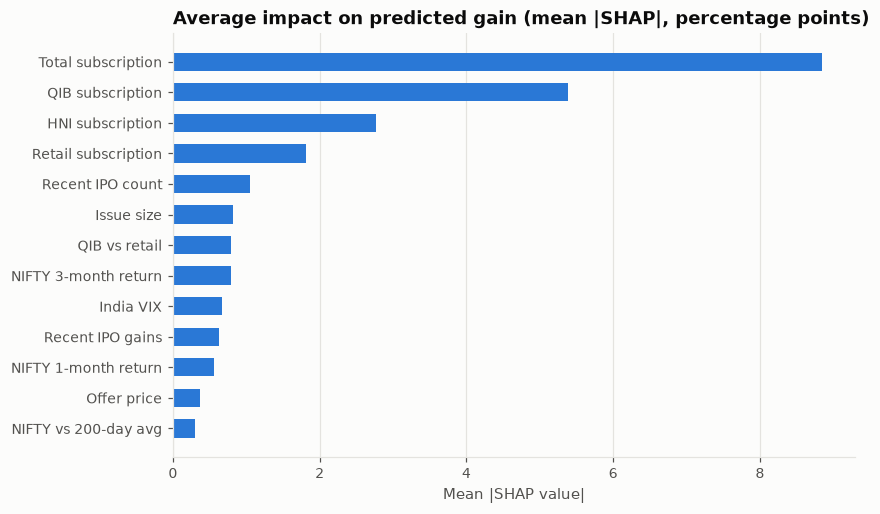

Total subscription     8.85
QIB subscription       5.38
HNI subscription       2.76
Retail subscription    1.81
Recent IPO count       1.05
Issue size             0.82
QIB vs retail          0.80
NIFTY 3-month return   0.79
India VIX              0.67
Recent IPO gains       0.63
NIFTY 1-month return   0.56
Offer price            0.37
NIFTY vs 200-day avg   0.30
dtype: float64

In [10]:
deploy = joblib.load(MODELS_DIR / "deploy.pkl")
pipe = deploy["point"]
X = f[deploy["point_columns"]]
X_imputed = pd.DataFrame(pipe[:-1].transform(X), columns=X.columns)
explainer = shap.TreeExplainer(pipe[-1])
values = explainer(X_imputed)

labels = {"log_sub_total": "Total subscription", "log_sub_hni": "HNI subscription", "log_sub_qib": "QIB subscription",
          "log_sub_rii": "Retail subscription", "qib_to_rii": "QIB vs retail", "log_issue_size": "Issue size",
          "log_offer_price": "Offer price", "nifty_ret_1m": "NIFTY 1-month return", "nifty_ret_3m": "NIFTY 3-month return",
          "nifty_vs_200dma": "NIFTY vs 200-day avg", "vix": "India VIX", "recent_ipo_mean_gain": "Recent IPO gains",
          "recent_ipo_count": "Recent IPO count"}
importance = pd.Series(np.abs(values.values).mean(axis=0), index=[labels[c] for c in X.columns]).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Average impact on predicted gain (mean |SHAP|, percentage points)")
ax.set_xlabel("Mean |SHAP value|")
save(fig, "10_shap_importance")
plt.show()
importance.sort_values(ascending=False).round(2)

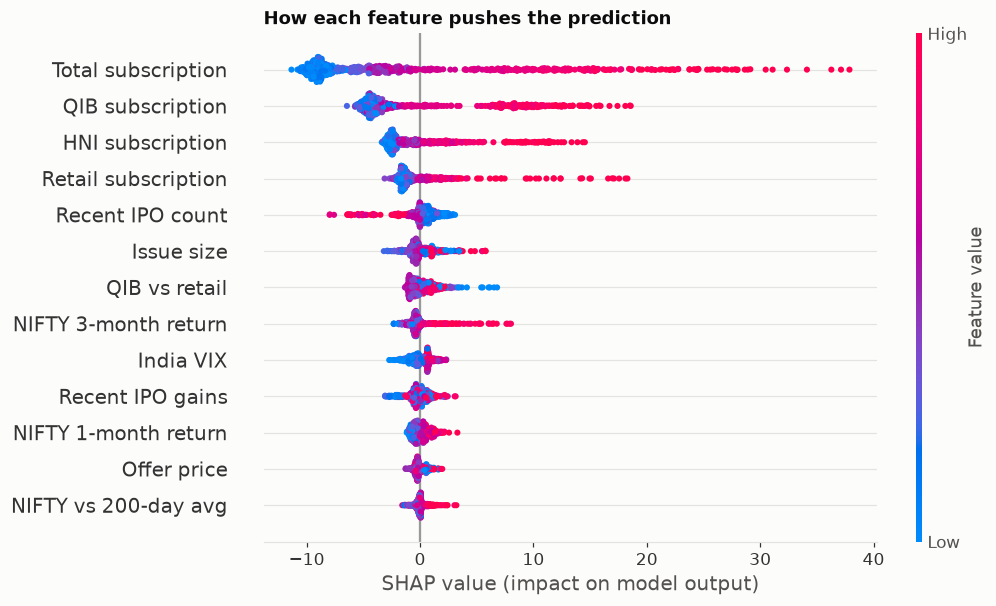

In [11]:
shap.plots.beeswarm(values.__class__(values.values, values.base_values, X_imputed.values,
                                     feature_names=[labels[c] for c in X.columns]), show=False, max_display=13)
plt.title("How each feature pushes the prediction", loc="left")
plt.gcf().set_size_inches(9, 6)
save(plt.gcf(), "11_shap_beeswarm")
plt.show()

## Summary

- Tuned on 2010–2023 with yearly folds; nothing was chosen on 2024–2026.
- A model frozen in 2023 failed on 2024–2026 because of subscription inflation; refitting every
  quarter (walk-forward) is both the realistic setup and the better one.
- The random forest ranks IPOs best (Spearman 0.71 out-of-sample) but does not beat a simple
  lookup on absolute error in 2024–2026.
- The 80% range is calibrated: 79% coverage out-of-sample.
- Subscription (total, then QIB and HNI) drives the prediction; market mood adjusts it.